In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os
from pathlib import Path
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

zip_path = Path("/content/MRI_Split_Dataset.zip")
extract_path = Path("/content/MRI_Split_Dataset")

if zip_path.exists() and not extract_path.exists():
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall("/content/MRI_Split_Dataset")
    print("Extraction complete!")

# Inspect extracted files to find the correct 'test' folder
base_dir = Path("/content/MRI_Split_Dataset")
test_dir = None

# Search for the directory named 'test' recursively
for root, dirs, files in os.walk(base_dir):
    if "test" in dirs:
        test_dir = Path(root) / "test"
        break

if test_dir is None:
    raise FileNotFoundError("Could not find a 'test' directory inside the extracted zip contents. Please verify the ZIP contents.")

print(f"Found test directory at: {test_dir}")

#Load the models (Already trained)
densenet_model = tf.keras.models.load_model("/content/best_class_weighted.keras")
efficientnet_model = tf.keras.models.load_model("/content/best_efficientnet.keras")

#prepare raw test dataset
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

raw_test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="int",
    class_names=["Normal", "Stroke", "Tumor"],
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

CLASS_NAMES = ["Normal", "Stroke", "Tumor"]

Extracting dataset...
Extraction complete!
Found test directory at: /content/MRI_Split_Dataset/test
Found 435 files belonging to 3 classes.


In [2]:
#Generate predictions for both models:
print("\nGenerating DenseNet predictions...")
# DenseNet uses preprocess_input from densenet module
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess

def prep_densenet(images, labels):
    return densenet_preprocess(images), labels

test_ds_densenet = raw_test_ds.map(prep_densenet).prefetch(tf.data.AUTOTUNE)
densenet_preds = densenet_model.predict(test_ds_densenet, verbose=1)

print("\nGenerating EfficientNet predictions...")
# EfficientNet in Keras has built-in preprocessing, so we just pass the raw images
def prep_efficientnet(images, labels):
    return images, labels

test_ds_efficientnet = raw_test_ds.map(prep_efficientnet).prefetch(tf.data.AUTOTUNE)
efficientnet_preds = efficientnet_model.predict(test_ds_efficientnet, verbose=1)

y_true = np.concatenate([labels.numpy() for images, labels in raw_test_ds])


Generating DenseNet predictions...
14/14 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step

Generating EfficientNet predictions...
14/14 ━━━━━━━━━━━━━━━━━━━━ 26s 801ms/step


In [3]:
#Find the optimal ensemble weights
best_acc = 0
best_weight = 0

# Test weights from 0.0 to 1.0 (0.05 increments)
for w in np.arange(0, 1.05, 0.05):
    # w = weight for DenseNet, (1-w) = weight for EfficientNet
    blended_preds = (densenet_preds * w) + (efficientnet_preds * (1 - w))
    preds_classes = np.argmax(blended_preds, axis=1)

    acc = accuracy_score(y_true, preds_classes)
    if acc > best_acc:
        best_acc = acc
        best_weight = w
print(f"DenseNet Weight:     {best_weight:.2f}")
print(f"EfficientNet Weight: {1 - best_weight:.2f}")
print(f"Ensemble Test Accuracy: {best_acc * 100:.2f}%")

DenseNet Weight:     0.40
EfficientNet Weight: 0.60
Ensemble Test Accuracy: 97.47%


              precision    recall  f1-score   support

      Normal     0.9504    0.9664    0.9583       119
      Stroke     0.9943    0.9665    0.9802       179
       Tumor     0.9714    0.9927    0.9819       137

    accuracy                         0.9747       435
   macro avg     0.9720    0.9752    0.9735       435
weighted avg     0.9751    0.9747    0.9748       435



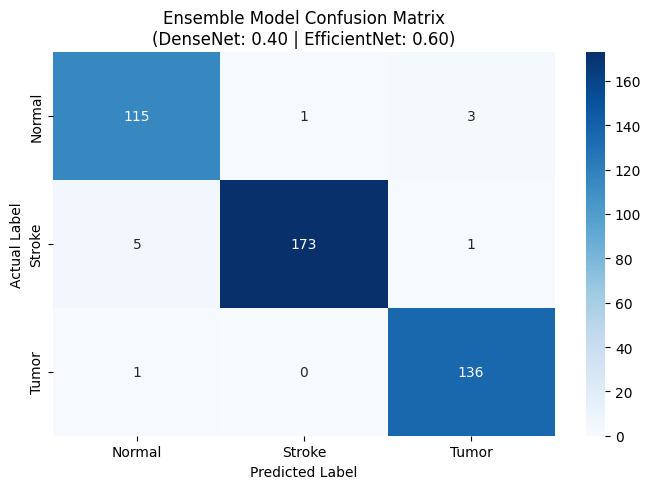

In [4]:
#Final Evaluation and Visualisation - Applying the best weights
final_preds_probs = (densenet_preds * best_weight) + (efficientnet_preds * (1 - best_weight))
final_preds_classes = np.argmax(final_preds_probs, axis=1)

#Classification report
print(classification_report(y_true, final_preds_classes, target_names=CLASS_NAMES, digits=4))

#Confusion Matrix visualisation
cm = confusion_matrix(y_true, final_preds_classes)
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title(f"Ensemble Model Confusion Matrix\n(DenseNet: {best_weight:.2f} | EfficientNet: {1-best_weight:.2f})")
plt.tight_layout()
plt.show()

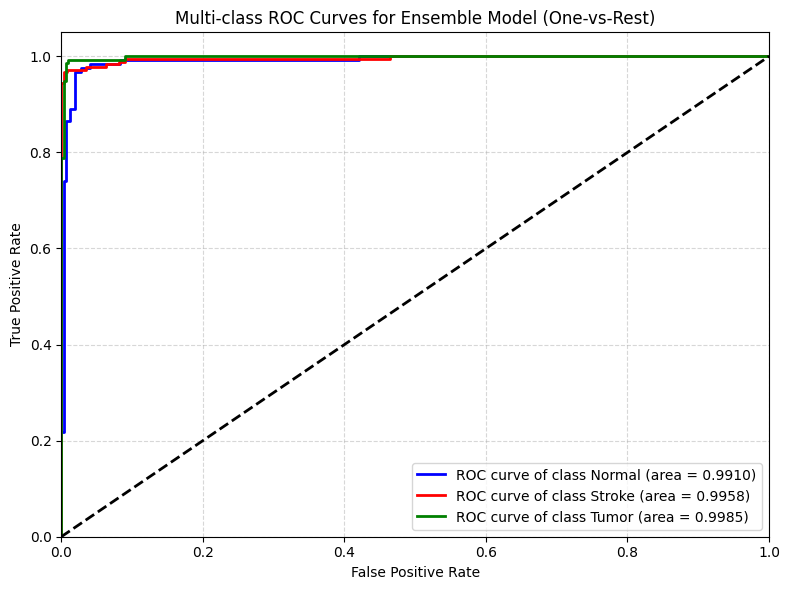

In [5]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Binarize the true labels for multi-class ROC calculation (One-vs-Rest)
y_true_bin = label_binarize(y_true, classes=[0, 1, 2])
n_classes = y_true_bin.shape[1]

# Calculate ROC curve and ROC area for each class using the final ensemble probabilities
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], final_preds_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
plt.figure(figsize=(8, 6))
colors = ['blue', 'red', 'green']

for i, color in enumerate(colors):
    plt.plot(
        fpr[i], tpr[i], color=color, lw=2,
        label=f'ROC curve of class {CLASS_NAMES[i]} (area = {roc_auc[i]:.4f})'
    )

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-class ROC Curves for Ensemble Model (One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Grad-CAM Implementation for Model Interpretability

To understand why our models make specific decisions, we can use Grad-CAM. This technique highlights the regions of the MRI scan that contributed most to the model's classification decision.

In [6]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.cm as cm

def get_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # Create a model that maps the input image to the activations of the last conv layer as well as the output predictions
    grad_model = tf.keras.models.Model(
        inputs=[model.inputs],
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    # Compute the gradient of the top predicted class (or selected class) for the input image
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # Gradient of the output neuron with respect to the output feature map of the last conv layer
    grads = tape.gradient(class_channel, last_conv_layer_output)

    # Mean intensity of the gradient over each feature map channel
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Multiply each channel in the feature map array by 'how important this channel is' with regard to the top predicted class
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalize the heatmap between 0 & 1
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

def display_gradcam(img, heatmap, alpha=0.4):
    # Rescale heatmap to a range 0-255
    heatmap = np.uint8(255 * heatmap)

    # Use jet colormap to colorize heatmap
    jet = cm.get_cmap("jet")

    # Use RGB values of the colormap
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]

    # Create an image with RGB colorized heatmap
    jet_heatmap = tf.keras.utils.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.shape[1], img.shape[0]))
    jet_heatmap = tf.keras.utils.img_to_array(jet_heatmap)

    # Superimpose the heatmap on original image
    superimposed_img = jet_heatmap * alpha + img
    superimposed_img = tf.keras.utils.array_to_img(superimposed_img)
    return superimposed_img

Target layer for DenseNet: relu
Target layer for EfficientNet: top_activation


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


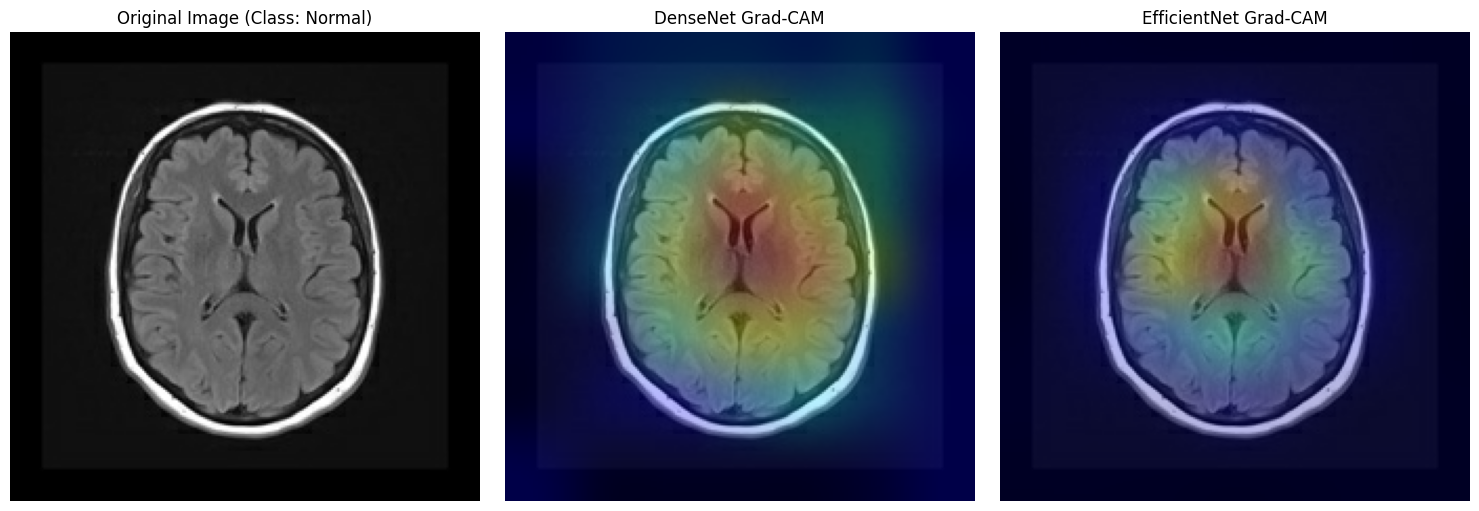

In [7]:
# Access the nested base models by scanning for the sub-model layers
def find_base_model(model):
    for layer in model.layers:
        # Check if the layer contains other layers (it's a Functional or Sequential sub-model)
        if hasattr(layer, 'layers'):
            return layer
    return None

densenet_base = find_base_model(densenet_model)
efficientnet_base = find_base_model(efficientnet_model)

if densenet_base is None or efficientnet_base is None:
    raise ValueError("Could not automatically locate the nested backbone models. Please check your model architecture.")

# Find the last convolutional layer inside the nested base models
densenet_target_layer = [l.name for l in densenet_base.layers if 'conv' in l.name or 'relu' in l.name][-1]
efficientnet_target_layer = [l.name for l in efficientnet_base.layers if 'conv' in l.name or 'activation' in l.name or 'add' in l.name][-1]

print(f"Target layer for DenseNet: {densenet_target_layer}")
print(f"Target layer for EfficientNet: {efficientnet_target_layer}")

# Adjust our Grad-CAM function dynamically for these nested models
def get_nested_gradcam_heatmap(img_array, outer_model, base_layer, target_layer_name, pred_index=None):
    # Reconstruct the model mapping base_model's input to target layer output and top predictions
    grad_model = tf.keras.models.Model(
        inputs=[base_layer.input],
        outputs=[base_layer.get_layer(target_layer_name).output, base_layer.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, base_predictions = grad_model(img_array)

        # Dynamically pass outputs through the remaining layers of the outer model
        x = base_predictions
        found_base = False
        for layer in outer_model.layers:
            if layer == base_layer:
                found_base = True
                continue
            if found_base:
                x = layer(x)
        preds = x

        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

# Updated display function using the modern non-deprecated Colormap API
def display_gradcam(img, heatmap, alpha=0.4):
    heatmap = np.uint8(255 * heatmap)
    jet = matplotlib.colormaps["jet"]
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]

    jet_heatmap = tf.keras.utils.array_to_img(jet_heatmap)
    jet_heatmap = jet_heatmap.resize((img.shape[1], img.shape[0]))
    jet_heatmap = tf.keras.utils.img_to_array(jet_heatmap)

    superimposed_img = jet_heatmap * alpha + img
    superimposed_img = tf.keras.utils.array_to_img(superimposed_img)
    return superimposed_img

import matplotlib
#sample image
for images, labels in raw_test_ds.take(1):
    sample_img = images[0].numpy()
    sample_label = labels[0].numpy()
    break

#Prepare inputs for prediction
img_input = np.expand_dims(sample_img, axis=0)

#Generate Heatmaps for Densenet
densenet_input = densenet_preprocess(img_input.copy())
densenet_heatmap = get_nested_gradcam_heatmap(densenet_input, densenet_model, densenet_base, densenet_target_layer)
densenet_cam = display_gradcam(sample_img, densenet_heatmap)

#Generate Heatmaps for EfficientNet
efficientnet_heatmap = get_nested_gradcam_heatmap(img_input.copy(), efficientnet_model, efficientnet_base, efficientnet_target_layer)
efficientnet_cam = display_gradcam(sample_img, efficientnet_heatmap)

#Plot the results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(sample_img.astype("uint8"))
axes[0].set_title(f"Original Image (Class: {CLASS_NAMES[sample_label]})")
axes[0].axis("off")

axes[1].imshow(densenet_cam)
axes[1].set_title("DenseNet Grad-CAM")
axes[1].axis("off")

axes[2].imshow(efficientnet_cam)
axes[2].set_title("EfficientNet Grad-CAM")
axes[2].axis("off")

plt.tight_layout()
plt.show()

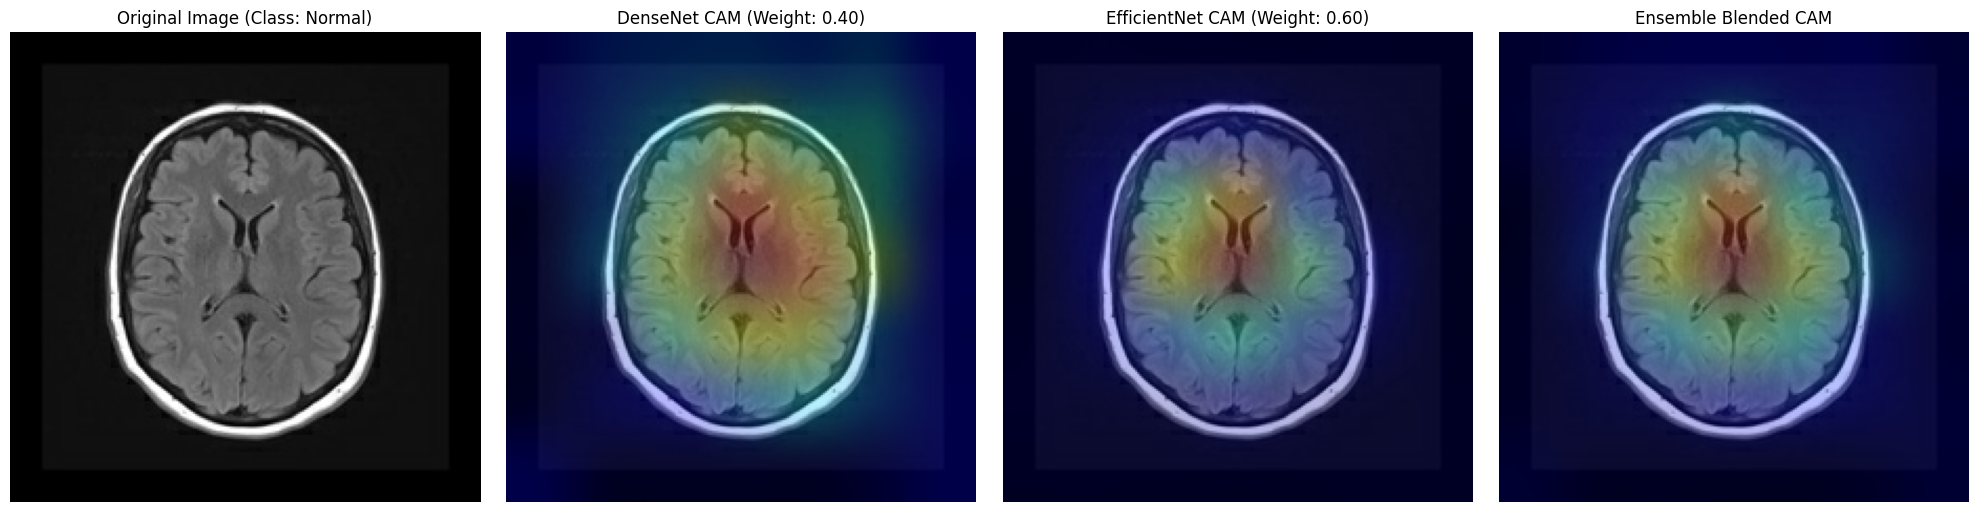

In [8]:
#Ensemble GradCAM
#Calculate individual heatmaps
densenet_input = densenet_preprocess(img_input.copy())
densenet_heatmap = get_nested_gradcam_heatmap(densenet_input, densenet_model, densenet_base, densenet_target_layer)

efficientnet_heatmap = get_nested_gradcam_heatmap(img_input.copy(), efficientnet_model, efficientnet_base, efficientnet_target_layer)

#Ensemble heatmap
ensemble_heatmap = (densenet_heatmap * best_weight) + (efficientnet_heatmap * (1.0 - best_weight))

# Normalize the blended heatmap back to [0, 1]
ensemble_heatmap = np.maximum(ensemble_heatmap, 0)
ensemble_heatmap = ensemble_heatmap / np.max(ensemble_heatmap)

# Overlay on the original image
ensemble_cam = display_gradcam(sample_img, ensemble_heatmap)

#Plot individual model heatmaps alongside the combined ensemble heatmap
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(sample_img.astype("uint8"))
axes[0].set_title(f"Original Image (Class: {CLASS_NAMES[sample_label]})")
axes[0].axis("off")

axes[1].imshow(densenet_cam)
axes[1].set_title(f"DenseNet CAM (Weight: {best_weight:.2f})")
axes[1].axis("off")

axes[2].imshow(efficientnet_cam)
axes[2].set_title(f"EfficientNet CAM (Weight: {1.0 - best_weight:.2f})")
axes[2].axis("off")

axes[3].imshow(ensemble_cam)
axes[3].set_title("Ensemble Blended CAM")
axes[3].axis("off")

plt.tight_layout()
plt.show()

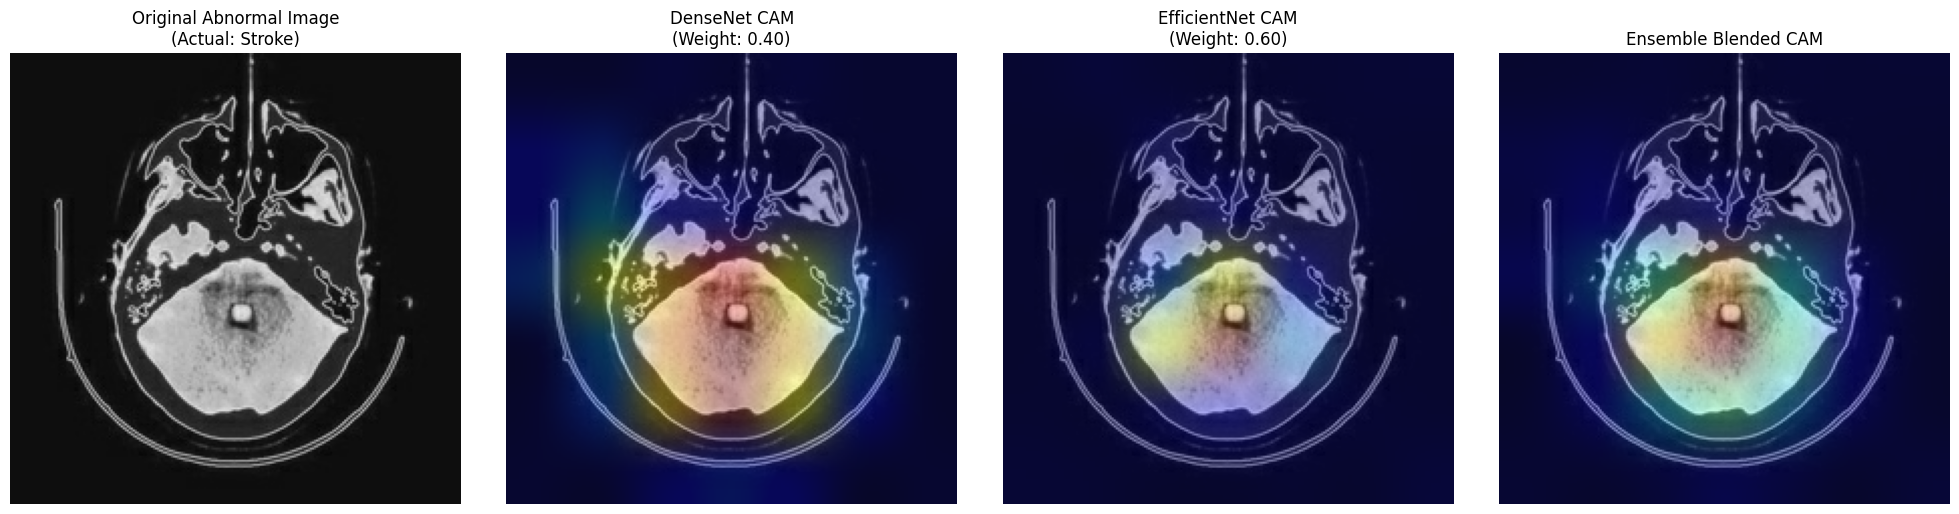

In [9]:
#GradCAM prediction for abnormal MRI
abnormal_img = None
abnormal_label = None

for images, labels in raw_test_ds:
    found = False
    for i in range(len(labels)):
        label_val = labels[i].numpy()
        if label_val in [1, 2]:  # Stroke (1) or Tumor (2)
            abnormal_img = images[i].numpy()
            abnormal_label = label_val
            found = True
            break
    if found:
        break

if abnormal_img is not None:
    # Prepare inputs for prediction
    abnormal_input = np.expand_dims(abnormal_img, axis=0)

    #Individual heatmaps
    dens_abnormal_input = densenet_preprocess(abnormal_input.copy())
    dens_heatmap = get_nested_gradcam_heatmap(dens_abnormal_input, densenet_model, densenet_base, densenet_target_layer)
    dens_cam = display_gradcam(abnormal_img, dens_heatmap)

    eff_heatmap = get_nested_gradcam_heatmap(abnormal_input.copy(), efficientnet_model, efficientnet_base, efficientnet_target_layer)
    eff_cam = display_gradcam(abnormal_img, eff_heatmap)

    #Ensemble heatmaps
    ens_heatmap = (dens_heatmap * best_weight) + (eff_heatmap * (1.0 - best_weight))
    ens_heatmap = np.maximum(ens_heatmap, 0)
    ens_heatmap = ens_heatmap / np.max(ens_heatmap)
    ens_cam = display_gradcam(abnormal_img, ens_heatmap)

    #Plot the results side-by-side
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    axes[0].imshow(abnormal_img.astype("uint8"))
    axes[0].set_title(f"Original Abnormal Image\n(Actual: {CLASS_NAMES[abnormal_label]})")
    axes[0].axis("off")

    axes[1].imshow(dens_cam)
    axes[1].set_title(f"DenseNet CAM\n(Weight: {best_weight:.2f})")
    axes[1].axis("off")

    axes[2].imshow(eff_cam)
    axes[2].set_title(f"EfficientNet CAM\n(Weight: {1.0 - best_weight:.2f})")
    axes[2].axis("off")

    axes[3].imshow(ens_cam)
    axes[3].set_title("Ensemble Blended CAM")
    axes[3].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Could not find any abnormal scans in the raw_test_ds batch.")